# Voice Deepfake Detection - Training Pipeline

This notebook trains a MobileNetV2-based model to detect spoofed audio using 1-second spectrogram windows.

**Dataset:** LA (Logical Access) and PA (Physical Access) from ASVspoof 2019
- **LA**: Spoofed voices via synthesis/voice conversion
- **PA**: Playback attacks (replaying voice recordings)

**Strategy:** Use only readable FLAC files, split them into 1-second windows, and balance spoof vs bonafide windows within each corpus before training.

In [1]:
print("test")

test


In [2]:
import os
import sys
import math
import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm


In [3]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

try:
    import tensorboard
    print(f"TensorBoard version: {tensorboard.__version__}")
except Exception as exc:
    print(f"TensorBoard import check failed: {exc}")

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

TensorFlow version: 2.21.0
GPU Available: []
TensorBoard version: 2.20.0


In [4]:
# Paths
FLAC_LA_DIR = Path("../data/flac_sample/LA")
FLAC_PA_DIR = Path("../data/flac_sample/PA")
LA_LABELS_CSV = Path("../data/flac_sample/LA_sample_labels.csv")
PA_LABELS_CSV = Path("../data/flac_sample/PA_sample_labels.csv")
MODEL_SAVE_PATH = "models/voice_detector_model.h5"
PLOT_DIR = Path("plots")
PLOT_DIR.mkdir(exist_ok=True)

## Step 1: Load & Explore Data

In [5]:
# Load labels for LA and PA corpora
la_labels = pd.read_csv(LA_LABELS_CSV)
pa_labels = pd.read_csv(PA_LABELS_CSV)

# Add corpus column for distinction
la_labels['corpus'] = 'LA'
pa_labels['corpus'] = 'PA'

# Combine and shuffle
all_labels = pd.concat([la_labels, pa_labels], ignore_index=True)
all_labels = all_labels.sample(frac=1, random_state=42).reset_index(drop=True)

print("Dataset Overview:")
print(f"Total samples: {len(all_labels)}")
print(f"\nLA corpus: {len(la_labels)} samples")
print(f"  - Bonafide (0): {(la_labels['label'] == 0).sum()}")
print(f"  - Spoof (1): {(la_labels['label'] == 1).sum()}")
print(f"\nPA corpus: {len(pa_labels)} samples")
print(f"  - Bonafide (0): {(pa_labels['label'] == 0).sum()}")
print(f"  - Spoof (1): {(pa_labels['label'] == 1).sum()}")
print(f"\nCombined (shuffled):")
print(f"  - Bonafide (0): {(all_labels['label'] == 0).sum()}")
print(f"  - Spoof (1): {(all_labels['label'] == 1).sum()}")
print(f"\nLabel distribution:\n{all_labels['label'].value_counts()}")
print(f"\nFirst 5 rows:\n{all_labels.head()}")

Dataset Overview:
Total samples: 8000

LA corpus: 4000 samples
  - Bonafide (0): 2000
  - Spoof (1): 2000

PA corpus: 4000 samples
  - Bonafide (0): 2000
  - Spoof (1): 2000

Combined (shuffled):
  - Bonafide (0): 4000
  - Spoof (1): 4000

Label distribution:
label
1    4000
0    4000
Name: count, dtype: int64

First 5 rows:
             id  label corpus
0  LA_E_9037359      1     LA
1  LA_E_5076224      0     LA
2  LA_E_7934220      0     LA
3  LA_E_3534768      1     LA
4  PA_E_1784580      1     PA


In [6]:
# Check file availability and audio integrity, then keep only valid files
print("Checking FLAC files...")
missing_files = []
unreadable_files = []
audio_stats = []
valid_indices = []

for idx, row in all_labels.iterrows():
    corpus = row['corpus']
    file_id = row['id']
    base_dir = FLAC_LA_DIR if corpus == 'LA' else FLAC_PA_DIR
    audio_path = base_dir / f"{file_id}.flac"
    
    if not audio_path.exists():
        missing_files.append((corpus, file_id, audio_path))
        continue

    try:
        data, sr = sf.read(str(audio_path), dtype='float32')
        audio_stats.append({
            'corpus': corpus,
            'id': file_id,
            'audio_path': str(audio_path),
            'sample_rate': sr,
            'duration_sec': len(data) / sr if sr > 0 else 0.0,
            'samples': len(data)
        })
        valid_indices.append(idx)
    except Exception as e:
        unreadable_files.append((corpus, file_id, audio_path, str(e)))

if missing_files:
    print(f"⚠️ Missing files: {len(missing_files)}")
    for corpus, fid, path in missing_files[:5]:
        print(f"  - {corpus}/{fid}: {path}")

if unreadable_files:
    print(f"⚠️ Unreadable FLAC files: {len(unreadable_files)}")
    for corpus, fid, path, err in unreadable_files[:10]:
        print(f"  - {corpus}/{fid}: {err}")

removed_count = len(all_labels) - len(valid_indices)
if removed_count > 0:
    all_labels = all_labels.loc[valid_indices].reset_index(drop=True)
    print(f"\nFiltered out {removed_count} invalid samples.")
else:
    print("✅ All audio files are readable!")

if audio_stats:
    print(f"\nAudio Statistics (from {len(audio_stats)} valid samples):")
    stats_df = pd.DataFrame(audio_stats)
    print(stats_df.groupby('corpus')[['sample_rate', 'duration_sec']].describe())
    all_labels['audio_path'] = all_labels.apply(
        lambda row: str((FLAC_LA_DIR if row['corpus'] == 'LA' else FLAC_PA_DIR) / f"{row['id']}.flac"),
        axis=1
    )
else:
    print("\nNo valid audio found after integrity check.")

Checking FLAC files...
⚠️ Unreadable FLAC files: 1746
  - LA/LA_E_9037359: Error : unknown error in flac decoder.
  - LA/LA_E_7934220: Error : flac decoder lost sync.
  - LA/LA_E_2485206: Error : unknown error in flac decoder.
  - LA/LA_E_3962205: Internal psf_fseek() failed.
  - LA/LA_E_5612408: Internal psf_fseek() failed.
  - LA/LA_E_1736309: Error : unknown error in flac decoder.
  - LA/LA_E_8774813: Error : unknown error in flac decoder.
  - LA/LA_E_6003996: Error : unknown error in flac decoder.
  - LA/LA_E_8458226: Internal psf_fseek() failed.
  - LA/LA_E_8823801: Error : unknown error in flac decoder.

Filtered out 1746 invalid samples.

Audio Statistics (from 6254 valid samples):
       sample_rate                                                             \
             count     mean  std      min      25%      50%      75%      max   
corpus                                                                          
LA          2254.0  16000.0  0.0  16000.0  16000.0  16000.0

## Step 2: Build 1-Second Window Metadata and Spectrograms

In [7]:
WINDOW_SEC = 1.0
TARGET_SAMPLE_RATE = 16000
TARGET_IMAGE_SIZE = (224, 224)

import importlib
import subprocess
import tempfile

def _resolve_audioprocessor_dir() -> Path:
    """Locate the Rust crate directory regardless of notebook working directory."""
    candidates = [
        Path.cwd() / "audioprocessor",
        Path.cwd().parent / "audioprocessor",
        Path("../audioprocessor").resolve(),
    ]
    for candidate in candidates:
        if (candidate / "Cargo.toml").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find audioprocessor/Cargo.toml from the current notebook working directory."
    )

AUDIOPROCESSOR_DIR = _resolve_audioprocessor_dir()

def _build_and_install_rust_module(crate_dir: Path):
    """Build wheel with maturin and install it with pip (works without active virtualenv)."""
    wheel_out_dir = Path(tempfile.mkdtemp(prefix="audioprocessor_wheels_"))

    build_result = subprocess.run(
        [
            sys.executable,
            "-m",
            "maturin",
            "build",
            "--features",
            "python",
            "--interpreter",
            sys.executable,
            "--out",
            str(wheel_out_dir),
        ],
        cwd=str(crate_dir),
        check=False,
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
    )
    if build_result.returncode != 0:
        raise RuntimeError(
            "maturin build failed.\n"
            f"stdout:\n{build_result.stdout}\n"
            f"stderr:\n{build_result.stderr}"
        )

    wheels = sorted(wheel_out_dir.glob("audioprocessor-*.whl"))
    if not wheels:
        raise RuntimeError(
            f"No wheel file was produced in {wheel_out_dir}.\n"
            f"maturin stdout:\n{build_result.stdout}\n"
            f"maturin stderr:\n{build_result.stderr}"
        )

    install_result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--force-reinstall", str(wheels[-1])],
        check=False,
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
    )
    if install_result.returncode != 0:
        raise RuntimeError(
            "pip install of audioprocessor wheel failed.\n"
            f"stdout:\n{install_result.stdout}\n"
            f"stderr:\n{install_result.stderr}"
        )


def _ensure_rust_module():
    """Import audioprocessor module, and auto-build/install it when missing."""
    try:
        return importlib.import_module("audioprocessor")
    except ImportError:
        print(f"audioprocessor module not found. Building wheel with maturin in {AUDIOPROCESSOR_DIR}...")
        _build_and_install_rust_module(AUDIOPROCESSOR_DIR)
        importlib.invalidate_caches()
        return importlib.import_module("audioprocessor")

audioprocessor = _ensure_rust_module()

lfcc_converter = audioprocessor.LfccSpectrogramConverter(
    sample_rate=TARGET_SAMPLE_RATE,
    pre_emphasis_alpha=0.97,
    frame_length_ms=25.0,
    frame_step_ms=10.0,
    num_linear_filters=40,
    num_cepstral_coeffs=20,
    fft_size=512,
)

def build_window_metadata(files_df, window_sec=WINDOW_SEC, sample_rate=TARGET_SAMPLE_RATE, include_partial_last=True):
    """Build one-second window metadata for each readable FLAC file."""
    window_rows = []
    
    for _, row in tqdm(files_df.iterrows(), total=len(files_df), desc='Building windows'):
        audio_path = Path(row['audio_path'])
        corpus = row['corpus']
        file_id = row['id']
        label = int(row['label'])
        info = sf.info(str(audio_path))
        file_sample_rate = info.samplerate
        total_frames = info.frames

        file_samples_per_window = int(round(window_sec * file_sample_rate))
        
        if include_partial_last:
            total_windows = math.ceil(total_frames / file_samples_per_window)
        else:
            total_windows = total_frames // file_samples_per_window
        
        for window_index in range(total_windows):
            start_sample = window_index * file_samples_per_window
            if start_sample >= total_frames:
                continue
            end_sample = min(start_sample + file_samples_per_window, total_frames)
            window_rows.append({
                'window_id': f"{corpus}_{file_id}_w{window_index:04d}",
                'corpus': corpus,
                'file_id': file_id,
                'label': label,
                'audio_path': str(audio_path),
                'sample_rate': file_sample_rate,
                'window_sec': window_sec,
                'window_index': window_index,
                'window_start_sample': start_sample,
                'window_end_sample': end_sample,
                'window_frames': end_sample - start_sample
            })
    
    return pd.DataFrame(window_rows)

def audio_to_spectrogram(audio, sample_rate, target_size=TARGET_IMAGE_SIZE):
    """Convert a 1-second waveform window into normalized HWC image using Rust LFCC converter."""
    if audio.ndim > 1:
        audio = np.mean(audio, axis=1)

    if len(audio) == 0:
        audio = np.zeros(sample_rate, dtype=np.float32)

    if sample_rate != TARGET_SAMPLE_RATE:
        raise ValueError(f"Expected sample_rate={TARGET_SAMPLE_RATE}, got {sample_rate}.")

    rust_out = lfcc_converter.convert_window(audio.astype(np.float32).tolist())
    spec = np.array(rust_out, dtype=np.float32).reshape(3, target_size[0], target_size[1])
    spec = np.transpose(spec, (1, 2, 0))  # CHW -> HWC
    spec = spec - spec.min()
    spec = spec / (spec.max() - spec.min() + 1e-8)
    return spec.astype(np.float32)

print("Building 1-second window metadata from readable FLAC files...")
window_df = build_window_metadata(all_labels, window_sec=WINDOW_SEC, sample_rate=TARGET_SAMPLE_RATE, include_partial_last=True)
print(f"Total windows: {len(window_df)}")
print(f"\nWindow label distribution:\n{window_df.groupby(['corpus', 'label']).size()}")
print(f"\nFirst 5 windows:\n{window_df.head()}")


Building 1-second window metadata from readable FLAC files...


Building windows: 100%|██████████| 6254/6254 [00:01<00:00, 4026.06it/s]

Total windows: 18836

Window label distribution:
corpus  label
LA      0        4209
        1        3324
PA      0        5610
        1        5693
dtype: int64

First 5 windows:
               window_id corpus       file_id  label  \
0  LA_LA_E_5076224_w0000     LA  LA_E_5076224      0   
1  LA_LA_E_5076224_w0001     LA  LA_E_5076224      0   
2  LA_LA_E_5076224_w0002     LA  LA_E_5076224      0   
3  LA_LA_E_5076224_w0003     LA  LA_E_5076224      0   
4  LA_LA_E_3534768_w0000     LA  LA_E_3534768      1   

                                 audio_path  sample_rate  window_sec  \
0  ..\data\flac_sample\LA\LA_E_5076224.flac        16000         1.0   
1  ..\data\flac_sample\LA\LA_E_5076224.flac        16000         1.0   
2  ..\data\flac_sample\LA\LA_E_5076224.flac        16000         1.0   
3  ..\data\flac_sample\LA\LA_E_5076224.flac        16000         1.0   
4  ..\data\flac_sample\LA\LA_E_3534768.flac        16000         1.0   

   window_index  window_start_sample  window_end

## Step 3: Load 1-Second Window Spectrograms & Visualize

Loading sample 1-second window spectrograms...


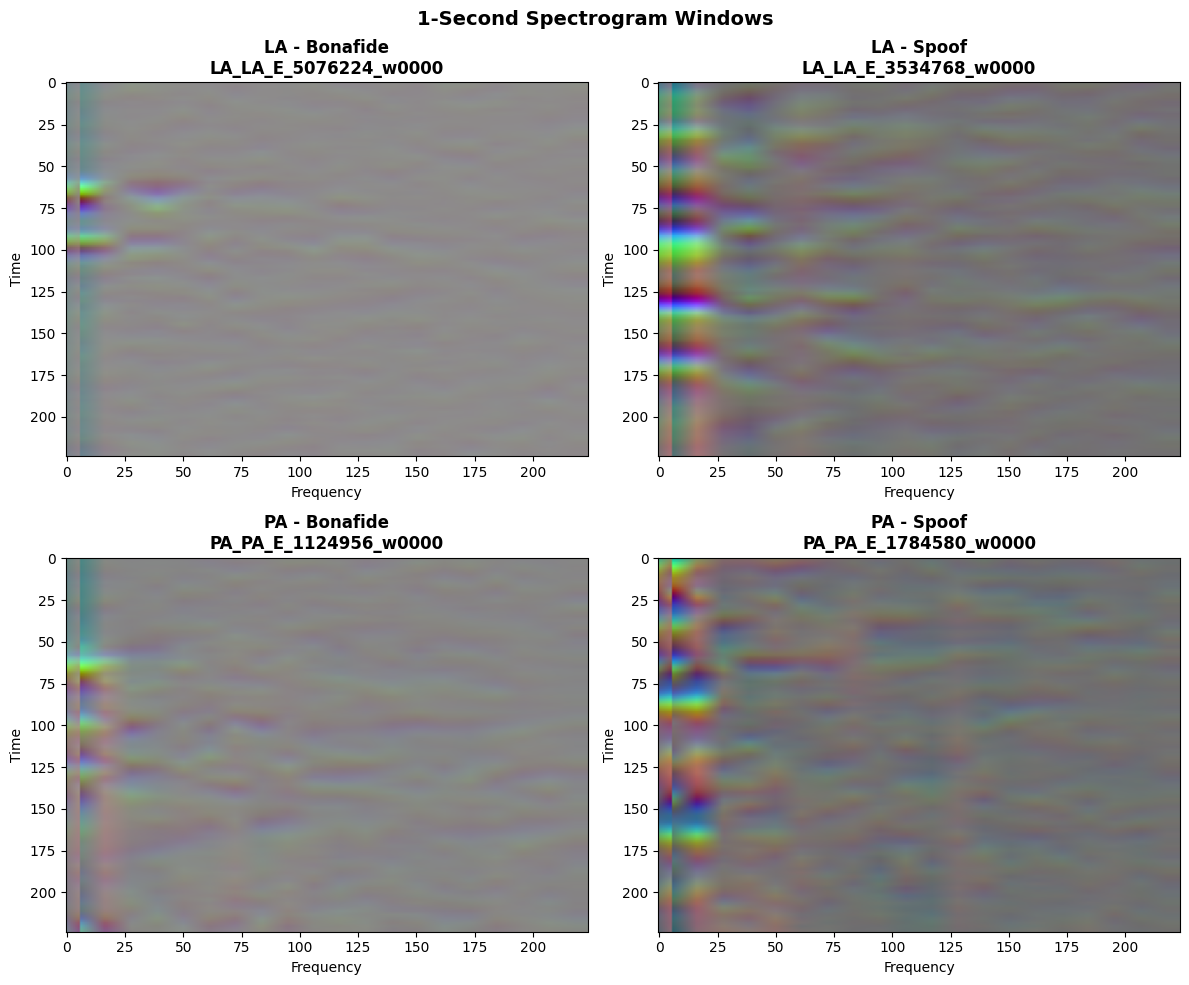

✅ Sample window spectrograms saved to plots/


In [8]:
def load_window_spectrogram(window_row):
    """Load a 1-second audio window and convert it into a spectrogram image."""
    try:
        audio_path = window_row['audio_path']
        start_sample = int(window_row['window_start_sample'])
        window_frames = int(window_row['window_frames'])
        sample_rate = int(window_row['sample_rate'])
        
        audio, sr = sf.read(
            str(audio_path),
            start=start_sample,
            frames=window_frames,
            dtype='float32',
            always_2d=False
        )
        
        if sr != sample_rate:
            sample_rate = sr
        
        if len(audio) < int(sample_rate * WINDOW_SEC):
            pad_len = int(sample_rate * WINDOW_SEC) - len(audio)
            if audio.ndim == 1:
                audio = np.pad(audio, (0, pad_len))
            else:
                audio = np.pad(audio, ((0, pad_len), (0, 0)))
        
        spec = audio_to_spectrogram(audio, sample_rate, target_size=TARGET_IMAGE_SIZE)
        return spec
    except Exception as e:
        print(f"Error loading window {window_row['window_id']}: {e}")
        return None

print("Loading sample 1-second window spectrograms...")
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('1-Second Spectrogram Windows', fontsize=14, fontweight='bold')

samples_to_viz = [
    (window_df[(window_df['corpus'] == 'LA') & (window_df['label'] == 0)].iloc[0], 'LA - Bonafide', (0, 0)),
    (window_df[(window_df['corpus'] == 'LA') & (window_df['label'] == 1)].iloc[0], 'LA - Spoof', (0, 1)),
    (window_df[(window_df['corpus'] == 'PA') & (window_df['label'] == 0)].iloc[0], 'PA - Bonafide', (1, 0)),
    (window_df[(window_df['corpus'] == 'PA') & (window_df['label'] == 1)].iloc[0], 'PA - Spoof', (1, 1)),
]

for row, title, ax_pos in samples_to_viz:
    spec = load_window_spectrogram(row)
    if spec is not None:
        axes[ax_pos].imshow(spec, cmap='viridis', aspect='auto')
    else:
        axes[ax_pos].text(0.5, 0.5, 'Error loading', ha='center', va='center')
    axes[ax_pos].set_title(f"{title}\n{row['window_id']}", fontweight='bold')
    axes[ax_pos].set_xlabel('Frequency')
    axes[ax_pos].set_ylabel('Time')

plt.tight_layout()
plt.savefig(PLOT_DIR / 'sample_window_spectrograms.png', dpi=100, bbox_inches='tight')
plt.show()
print("✅ Sample window spectrograms saved to plots/")

## Step 4: Build Balanced Window Data Pipeline (Train/Val/Test Split)

In [9]:
def balance_window_df(data_df, label_col='label', random_state=42):
    """Downsample the majority class so spoof and bonafide windows are balanced."""
    class_counts = data_df[label_col].value_counts()
    if len(class_counts) < 2:
        return data_df.sample(frac=1, random_state=random_state).reset_index(drop=True)
    
    target_count = class_counts.min()
    balanced_parts = []
    for label_value in sorted(class_counts.index.tolist()):
        subset = data_df[data_df[label_col] == label_value]
        balanced_parts.append(subset.sample(n=target_count, random_state=random_state))
    
    balanced_df = pd.concat(balanced_parts, ignore_index=True)
    return balanced_df.sample(frac=1, random_state=random_state).reset_index(drop=True)

def split_files_and_windows(file_df, corpus_name, all_windows_df, random_state=42):
    """Split at file level first, then build balanced window splits."""
    train_files, temp_files = train_test_split(
        file_df, test_size=0.3, random_state=random_state, stratify=file_df['label']
    )
    val_files, test_files = train_test_split(
        temp_files, test_size=0.5, random_state=random_state, stratify=temp_files['label']
    )

    train_windows = all_windows_df[all_windows_df['file_id'].isin(train_files['id'])].copy()
    val_windows = all_windows_df[all_windows_df['file_id'].isin(val_files['id'])].copy()
    test_windows = all_windows_df[all_windows_df['file_id'].isin(test_files['id'])].copy()

    train_windows = balance_window_df(train_windows, random_state=random_state)
    val_windows = balance_window_df(val_windows, random_state=random_state)
    test_windows = balance_window_df(test_windows, random_state=random_state)

    print(f"{corpus_name} Dataset Split (balanced windows):")
    print(f"  Files - Train: {len(train_files)} | Val: {len(val_files)} | Test: {len(test_files)}")
    print(f"  Windows - Train: {len(train_windows)} | Val: {len(val_windows)} | Test: {len(test_windows)}")
    print(f"  Train label counts:\n{train_windows['label'].value_counts().sort_index()}")
    print(f"  Val label counts:\n{val_windows['label'].value_counts().sort_index()}")
    print(f"  Test label counts:\n{test_windows['label'].value_counts().sort_index()}")

    return train_windows, val_windows, test_windows

la_file_data = all_labels[all_labels['corpus'] == 'LA'].reset_index(drop=True)
pa_file_data = all_labels[all_labels['corpus'] == 'PA'].reset_index(drop=True)

la_windows = window_df[window_df['corpus'] == 'LA'].reset_index(drop=True)
pa_windows = window_df[window_df['corpus'] == 'PA'].reset_index(drop=True)

la_train, la_val, la_test = split_files_and_windows(la_file_data, 'LA', la_windows)
pa_train, pa_val, pa_test = split_files_and_windows(pa_file_data, 'PA', pa_windows)

# Combined test set for ensemble evaluation (balanced per corpus, then combined)
combined_test = pd.concat([la_test, pa_test], ignore_index=True)
print(f"\nCombined Test Set: {len(combined_test)} windows (LA: {len(la_test)}, PA: {len(pa_test)})")


LA Dataset Split (balanced windows):
  Files - Train: 1577 | Val: 338 | Test: 339
  Windows - Train: 4666 | Val: 1008 | Test: 974
  Train label counts:
label
0    2333
1    2333
Name: count, dtype: int64
  Val label counts:
label
0    504
1    504
Name: count, dtype: int64
  Test label counts:
label
0    487
1    487
Name: count, dtype: int64
PA Dataset Split (balanced windows):
  Files - Train: 2800 | Val: 600 | Test: 600
  Windows - Train: 7850 | Val: 1648 | Test: 1696
  Train label counts:
label
0    3925
1    3925
Name: count, dtype: int64
  Val label counts:
label
0    824
1    824
Name: count, dtype: int64
  Test label counts:
label
0    848
1    848
Name: count, dtype: int64

Combined Test Set: 2670 windows (LA: 974, PA: 1696)


In [10]:
def data_generator(data_df, batch_size=32, augment=False, shuffle=True):
    """
    TensorFlow data generator that loads 1-second audio windows and converts them to spectrogram images.
    
    Args:
        data_df: DataFrame with window metadata
        batch_size: Batch size
        augment: Enable data augmentation
        shuffle: Shuffle data
    """
    if shuffle:
        data_df = data_df.sample(frac=1, random_state=None).reset_index(drop=True)
    
    def get_image_label(idx):
        row = data_df.iloc[idx]
        label = int(row['label'])
        
        try:
            audio, sr = sf.read(
                str(row['audio_path']),
                start=int(row['window_start_sample']),
                frames=int(row['window_frames']),
                dtype='float32',
                always_2d=False
            )
            
            target_length = int(sr * WINDOW_SEC)
            if len(audio) < target_length:
                pad_len = target_length - len(audio)
                if audio.ndim == 1:
                    audio = np.pad(audio, (0, pad_len))
                else:
                    audio = np.pad(audio, ((0, pad_len), (0, 0)))
            
            spec = audio_to_spectrogram(audio, sr, target_size=TARGET_IMAGE_SIZE)
        except Exception as e:
            print(f"Error loading {row['window_id']}: {e}")
            spec = np.zeros((TARGET_IMAGE_SIZE[0], TARGET_IMAGE_SIZE[1], 3), dtype=np.float32)
        
        if augment:
            if np.random.rand() > 0.5:
                spec = np.fliplr(spec)
            if np.random.rand() > 0.5:
                spec = np.flipud(spec)
            spec = spec * np.random.uniform(0.9, 1.1)
            spec = np.clip(spec, 0, 1)
        
        return spec.astype(np.float32), np.float32(label)
    
    def generator():
        for idx in range(len(data_df)):
            spec, label = get_image_label(idx)
            yield spec, label
    
    dataset = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(TARGET_IMAGE_SIZE[0], TARGET_IMAGE_SIZE[1], 3), dtype=tf.float32),
            tf.TensorSpec(shape=(), dtype=tf.float32)
        )
    )
    
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

# Create datasets for LA (Model 1)
print("Creating LA data pipelines...")
BATCH_SIZE = 32

la_train_dataset = data_generator(la_train, batch_size=BATCH_SIZE, augment=True, shuffle=True)
la_val_dataset = data_generator(la_val, batch_size=BATCH_SIZE, augment=False, shuffle=False)
la_test_dataset = data_generator(la_test, batch_size=BATCH_SIZE, augment=False, shuffle=False)

# Create datasets for PA (Model 2)
print("Creating PA data pipelines...")
pa_train_dataset = data_generator(pa_train, batch_size=BATCH_SIZE, augment=True, shuffle=True)
pa_val_dataset = data_generator(pa_val, batch_size=BATCH_SIZE, augment=False, shuffle=False)
pa_test_dataset = data_generator(pa_test, batch_size=BATCH_SIZE, augment=False, shuffle=False)

print("✅ All datasets created successfully!")
print(f"\nLA Dataset:")
print(f"  Train: {len(la_train)} windows → {max(len(la_train)//BATCH_SIZE, 1)} batches")
print(f"  Val: {len(la_val)} windows → {max(len(la_val)//BATCH_SIZE, 1)} batches")
print(f"  Test: {len(la_test)} windows → {max(len(la_test)//BATCH_SIZE, 1)} batches")
print(f"\nPA Dataset:")
print(f"  Train: {len(pa_train)} windows → {max(len(pa_train)//BATCH_SIZE, 1)} batches")
print(f"  Val: {len(pa_val)} windows → {max(len(pa_val)//BATCH_SIZE, 1)} batches")
print(f"  Test: {len(pa_test)} windows → {max(len(pa_test)//BATCH_SIZE, 1)} batches")


Creating LA data pipelines...
Creating PA data pipelines...
✅ All datasets created successfully!

LA Dataset:
  Train: 4666 windows → 145 batches
  Val: 1008 windows → 31 batches
  Test: 974 windows → 30 batches

PA Dataset:
  Train: 7850 windows → 245 batches
  Val: 1648 windows → 51 batches
  Test: 1696 windows → 53 batches


## Step 5: Build Model (MobileNetV2 Transfer Learning)

In [11]:
# Build 2 MobileNetV2 models: one for LA, one for PA
def build_detector_model(corpus_name='LA', input_shape=(224, 224, 3)):
    """
    Build MobileNetV2-based binary classifier for voice deepfake detection.
    
    Args:
        corpus_name: 'LA' or 'PA' - for specific training
        input_shape: Input image shape (224, 224, 3)
    
    Returns:
        Compiled Keras model
    """
    # Set random seed for reproducibility
    seed = 42
    tf.random.set_seed(seed)
    np.random.seed(seed)
    
    # Load pretrained MobileNetV2 (ImageNet weights)
    base_model = MobileNetV2(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape
    )
    
    # Freeze base model for transfer learning
    base_model.trainable = False
    
    # Build custom top layers
    inputs = tf.keras.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(256, activation='relu', name='dense_256')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(128, activation='relu', name='dense_128')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(0.2)(x)
    outputs = tf.keras.layers.Dense(1, activation='sigmoid', name='output')(x)
    
    model = tf.keras.Model(inputs=inputs, outputs=outputs, name=f'detector_{corpus_name}')
    
    # Compile with Adam optimizer
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
    )
    
    return model, base_model

# Build Model for LA
print("Building Model for LA (Logical Access)...")
model_la, base_model_la = build_detector_model(corpus_name='LA')

# Build Model for PA
print("Building Model for PA (Physical Access)...")
model_pa, base_model_pa = build_detector_model(corpus_name='PA')

print("\n" + "=" * 60)
print("LA Model Architecture:")
print("=" * 60)
model_la.summary()

print("\n" + "=" * 60)
print("PA Model Architecture:")
print("=" * 60)
model_pa.summary()

print(f"\nLA Model parameters: {model_la.count_params():,}")
print(f"PA Model parameters: {model_pa.count_params():,}")

Building Model for LA (Logical Access)...
Building Model for PA (Physical Access)...

LA Model Architecture:


Model: "detector_LA"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,620,481 (10.00 MB)

 Trainable params: 361,729 (1.38 MB)

 Non-trainable params: 2,258,752 (8.62 MB)

... (3 outputs left out)

 Total params: 2,620,481 (10.00 MB)

 Trainable params: 361,729 (1.38 MB)

 Non-trainable params: 2,258,752 (8.62 MB)


LA Model parameters: 2,620,481
PA Model parameters: 2,620,481


## Step 6: Train Model

In [ ]:
# Setup callbacks for both models
os.makedirs('models', exist_ok=True)

def create_callbacks(model_name, corpus):
    """Create training callbacks for a specific model."""
    model_checkpoint = f"models/voice_detector_{corpus}.h5"
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=model_checkpoint,
            monitor='val_loss',
            save_best_only=True,
            mode='min',
            verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=10,
            restore_best_weights=True,
            verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=5,
            min_lr=1e-7,
            verbose=1
        )
    ]

    try:
        import tensorboard  # noqa: F401
        callbacks.append(
            tf.keras.callbacks.TensorBoard(
                log_dir=f'./logs/detector_{corpus}',
                update_freq='epoch',
                histogram_freq=0
            )
        )
    except ImportError:
        print(f"TensorBoard is not available; skipping TensorBoard callback for {corpus}.")

    return callbacks

# Train LA Model
print("\n" + "=" * 60)
print("Training LA Model (Logical Access)...")
print("=" * 60)

callbacks_la = create_callbacks('LA Model', 'LA')
history_la = model_la.fit(
    la_train_dataset,
    validation_data=la_val_dataset,
    epochs=50,
    callbacks=callbacks_la,
    verbose=1
)

print("\n✅ LA Model training complete!")

# Train PA Model
print("\n" + "=" * 60)
print("Training PA Model (Physical Access)...")
print("=" * 60)

callbacks_pa = create_callbacks('PA Model', 'PA')
history_pa = model_pa.fit(
    pa_train_dataset,
    validation_data=pa_val_dataset,
    epochs=50,
    callbacks=callbacks_pa,
    verbose=1
)

print("\n✅ PA Model training complete!")


Training LA Model (Logical Access)...
Epoch 1/50
    146/Unknown 345s 2s/step - accuracy: 0.5470 - loss: 0.8369 - precision: 0.5447 - recall: 0.5487

c:\Users\Hi\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from None to 0.64834, saving model to models/voice_detector_LA.h5



Epoch 1: finished saving model to models/voice_detector_LA.h5
146/146 ━━━━━━━━━━━━━━━━━━━━ 421s 3s/step - accuracy: 0.5763 - loss: 0.7885 - precision: 0.5760 - recall: 0.5782 - val_accuracy: 0.6071 - val_loss: 0.6483 - val_precision: 0.6055 - val_recall: 0.6151 - learning_rate: 1.0000e-04
Epoch 2/50
 33/146 ━━━━━━━━━━━━━━━━━━━━ 4:15 2s/step - accuracy: 0.5937 - loss: 0.7316 - precision: 0.5822 - recall: 0.5984

## Step 7: Visualize Training History

In [ ]:
# Plot training history for both models
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
fig.suptitle('Training History - LA and PA Models', fontsize=14, fontweight='bold')

# LA Model History
# Loss
axes[0, 0].plot(history_la.history['loss'], label='Train Loss', linewidth=2)
axes[0, 0].plot(history_la.history['val_loss'], label='Val Loss', linewidth=2)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('LA - Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Accuracy
axes[0, 1].plot(history_la.history['accuracy'], label='Train Acc', linewidth=2)
axes[0, 1].plot(history_la.history['val_accuracy'], label='Val Acc', linewidth=2)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].set_title('LA - Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Precision
axes[0, 2].plot(history_la.history['precision'], label='Train Precision', linewidth=2)
axes[0, 2].plot(history_la.history['val_precision'], label='Val Precision', linewidth=2)
axes[0, 2].set_xlabel('Epoch')
axes[0, 2].set_ylabel('Precision')
axes[0, 2].set_title('LA - Precision')
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

# Recall
axes[0, 3].plot(history_la.history['recall'], label='Train Recall', linewidth=2)
axes[0, 3].plot(history_la.history['val_recall'], label='Val Recall', linewidth=2)
axes[0, 3].set_xlabel('Epoch')
axes[0, 3].set_ylabel('Recall')
axes[0, 3].set_title('LA - Recall')
axes[0, 3].legend()
axes[0, 3].grid(True, alpha=0.3)

# PA Model History
# Loss
axes[1, 0].plot(history_pa.history['loss'], label='Train Loss', linewidth=2)
axes[1, 0].plot(history_pa.history['val_loss'], label='Val Loss', linewidth=2)
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Loss')
axes[1, 0].set_title('PA - Loss')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Accuracy
axes[1, 1].plot(history_pa.history['accuracy'], label='Train Acc', linewidth=2)
axes[1, 1].plot(history_pa.history['val_accuracy'], label='Val Acc', linewidth=2)
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Accuracy')
axes[1, 1].set_title('PA - Accuracy')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Precision
axes[1, 2].plot(history_pa.history['precision'], label='Train Precision', linewidth=2)
axes[1, 2].plot(history_pa.history['val_precision'], label='Val Precision', linewidth=2)
axes[1, 2].set_xlabel('Epoch')
axes[1, 2].set_ylabel('Precision')
axes[1, 2].set_title('PA - Precision')
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

# Recall
axes[1, 3].plot(history_pa.history['recall'], label='Train Recall', linewidth=2)
axes[1, 3].plot(history_pa.history['val_recall'], label='Val Recall', linewidth=2)
axes[1, 3].set_xlabel('Epoch')
axes[1, 3].set_ylabel('Recall')
axes[1, 3].set_title('PA - Recall')
axes[1, 3].legend()
axes[1, 3].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(PLOT_DIR / 'training_history_both_models.png', dpi=100, bbox_inches='tight')
plt.show()

print("✅ Training history plots saved to plots/")

## Step 8: Evaluate on Test Set

In [ ]:
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc, roc_auc_score
)

# Load best models
model_la_best = tf.keras.models.load_model('models/voice_detector_LA.h5')
model_pa_best = tf.keras.models.load_model('models/voice_detector_PA.h5')

print("=" * 60)
print("INDIVIDUAL MODEL EVALUATION")
print("=" * 60)

# Evaluate LA model on LA test set
print("\nLA Model on LA Test Set:")
la_loss, la_acc, la_prec, la_rec = model_la_best.evaluate(la_test_dataset, verbose=0)
print(f"  Loss: {la_loss:.4f} | Accuracy: {la_acc:.4f} | Precision: {la_prec:.4f} | Recall: {la_rec:.4f}")

# Evaluate PA model on PA test set
print("\nPA Model on PA Test Set:")
pa_loss, pa_acc, pa_prec, pa_rec = model_pa_best.evaluate(pa_test_dataset, verbose=0)
print(f"  Loss: {pa_loss:.4f} | Accuracy: {pa_acc:.4f} | Precision: {pa_prec:.4f} | Recall: {pa_rec:.4f}")

print("\n" + "=" * 60)
print("ENSEMBLE EVALUATION (on combined test set)")
print("=" * 60)

# Gather predictions from both models on combined test set
print("\nGathering ensemble predictions...")

all_predictions_la = []
all_predictions_pa = []
all_labels_ensemble = []
all_corpus_labels = []

# Predict on LA test set with both models
for spec_batch, label_batch in la_test_dataset:
    preds_la = model_la_best.predict(spec_batch, verbose=0)
    preds_pa = model_pa_best.predict(spec_batch, verbose=0)
    all_predictions_la.extend(preds_la.flatten())
    all_predictions_pa.extend(preds_pa.flatten())
    all_labels_ensemble.extend(label_batch.numpy())
    all_corpus_labels.extend(['LA'] * len(label_batch))

# Predict on PA test set with both models
for spec_batch, label_batch in pa_test_dataset:
    preds_la = model_la_best.predict(spec_batch, verbose=0)
    preds_pa = model_pa_best.predict(spec_batch, verbose=0)
    all_predictions_la.extend(preds_la.flatten())
    all_predictions_pa.extend(preds_pa.flatten())
    all_labels_ensemble.extend(label_batch.numpy())
    all_corpus_labels.extend(['PA'] * len(label_batch))

all_predictions_la = np.array(all_predictions_la)
all_predictions_pa = np.array(all_predictions_pa)
all_labels_ensemble = np.array(all_labels_ensemble)

# Ensemble: Average predictions from both models
ensemble_predictions = (all_predictions_la + all_predictions_pa) / 2.0
ensemble_binary = (ensemble_predictions > 0.5).astype(int)

# LA model only (on combined set)
la_model_binary = (all_predictions_la > 0.5).astype(int)

# PA model only (on combined set)
pa_model_binary = (all_predictions_pa > 0.5).astype(int)

print("\n📊 RESULTS SUMMARY:")
print("=" * 60)

# Calculate metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("\nLA Model (on combined test):")
la_acc = accuracy_score(all_labels_ensemble, la_model_binary)
la_prec = precision_score(all_labels_ensemble, la_model_binary, zero_division=0)
la_rec = recall_score(all_labels_ensemble, la_model_binary, zero_division=0)
la_f1 = f1_score(all_labels_ensemble, la_model_binary, zero_division=0)
la_auc = roc_auc_score(all_labels_ensemble, all_predictions_la)
print(f"  Accuracy: {la_acc:.4f} | Precision: {la_prec:.4f} | Recall: {la_rec:.4f} | F1: {la_f1:.4f} | AUC: {la_auc:.4f}")

print("\nPA Model (on combined test):")
pa_acc = accuracy_score(all_labels_ensemble, pa_model_binary)
pa_prec = precision_score(all_labels_ensemble, pa_model_binary, zero_division=0)
pa_rec = recall_score(all_labels_ensemble, pa_model_binary, zero_division=0)
pa_f1 = f1_score(all_labels_ensemble, pa_model_binary, zero_division=0)
pa_auc = roc_auc_score(all_labels_ensemble, all_predictions_pa)
print(f"  Accuracy: {pa_acc:.4f} | Precision: {pa_prec:.4f} | Recall: {pa_rec:.4f} | F1: {pa_f1:.4f} | AUC: {pa_auc:.4f}")

print("\n🎯 ENSEMBLE (Average of LA + PA):")
ens_acc = accuracy_score(all_labels_ensemble, ensemble_binary)
ens_prec = precision_score(all_labels_ensemble, ensemble_binary, zero_division=0)
ens_rec = recall_score(all_labels_ensemble, ensemble_binary, zero_division=0)
ens_f1 = f1_score(all_labels_ensemble, ensemble_binary, zero_division=0)
ens_auc = roc_auc_score(all_labels_ensemble, ensemble_predictions)
print(f"  Accuracy: {ens_acc:.4f} | Precision: {ens_prec:.4f} | Recall: {ens_rec:.4f} | F1: {ens_f1:.4f} | AUC: {ens_auc:.4f}")

print("\n" + "=" * 60)
print("Ensemble Classification Report:")
print(classification_report(all_labels_ensemble, ensemble_binary, target_names=['Bonafide', 'Spoof']))

# Confusion matrix for ensemble
cm_ensemble = confusion_matrix(all_labels_ensemble, ensemble_binary)
print(f"\nEnsemble Confusion Matrix:")
print(f"  TN: {cm_ensemble[0,0]}, FP: {cm_ensemble[0,1]}")
print(f"  FN: {cm_ensemble[1,0]}, TP: {cm_ensemble[1,1]}")

In [ ]:
# Visualize evaluation metrics - Model comparison
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Model & Ensemble Comparison', fontsize=14, fontweight='bold')

# ROC Curves
fpr_la, tpr_la, _ = roc_curve(all_labels_ensemble, all_predictions_la)
fpr_pa, tpr_pa, _ = roc_curve(all_labels_ensemble, all_predictions_pa)
fpr_ens, tpr_ens, _ = roc_curve(all_labels_ensemble, ensemble_predictions)

axes[0, 0].plot(fpr_la, tpr_la, linewidth=2, label=f'LA Model (AUC = {la_auc:.3f})')
axes[0, 0].plot(fpr_pa, tpr_pa, linewidth=2, label=f'PA Model (AUC = {pa_auc:.3f})')
axes[0, 0].plot(fpr_ens, tpr_ens, linewidth=2.5, label=f'Ensemble (AUC = {ens_auc:.3f})', linestyle='--')
axes[0, 0].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random')
axes[0, 0].set_xlabel('False Positive Rate')
axes[0, 0].set_ylabel('True Positive Rate')
axes[0, 0].set_title('ROC Curves Comparison')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Accuracy comparison
models = ['LA Model', 'PA Model', 'Ensemble']
accuracies = [la_acc, pa_acc, ens_acc]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
bars1 = axes[0, 1].bar(models, accuracies, color=colors, alpha=0.7)
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].set_title('Accuracy Comparison')
axes[0, 1].set_ylim([0, 1])
axes[0, 1].grid(True, alpha=0.3, axis='y')
for bar, acc in zip(bars1, accuracies):
    height = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2., height,
                   f'{acc:.3f}', ha='center', va='bottom', fontweight='bold')

# F1-Score comparison
f1_scores = [la_f1, pa_f1, ens_f1]
bars2 = axes[0, 2].bar(models, f1_scores, color=colors, alpha=0.7)
axes[0, 2].set_ylabel('F1-Score')
axes[0, 2].set_title('F1-Score Comparison')
axes[0, 2].set_ylim([0, 1])
axes[0, 2].grid(True, alpha=0.3, axis='y')
for bar, f1 in zip(bars2, f1_scores):
    height = bar.get_height()
    axes[0, 2].text(bar.get_x() + bar.get_width()/2., height,
                   f'{f1:.3f}', ha='center', va='bottom', fontweight='bold')

# Confusion Matrices
cm_la = confusion_matrix(all_labels_ensemble, la_model_binary)
cm_pa = confusion_matrix(all_labels_ensemble, pa_model_binary)

# LA Confusion Matrix
im1 = axes[1, 0].imshow(cm_la, interpolation='nearest', cmap=plt.cm.Blues)
axes[1, 0].figure.colorbar(im1, ax=axes[1, 0])
axes[1, 0].set(xticks=np.arange(2), yticks=np.arange(2),
               xticklabels=['Bonafide', 'Spoof'],
               yticklabels=['Bonafide', 'Spoof'])
axes[1, 0].set_ylabel('True Label')
axes[1, 0].set_xlabel('Predicted Label')
axes[1, 0].set_title('LA Model - Confusion Matrix')
for i in range(2):
    for j in range(2):
        axes[1, 0].text(j, i, f'{cm_la[i, j]}', ha='center', va='center',
                       color='white' if cm_la[i, j] > cm_la.max() / 2 else 'black')

# PA Confusion Matrix
im2 = axes[1, 1].imshow(cm_pa, interpolation='nearest', cmap=plt.cm.Blues)
axes[1, 1].figure.colorbar(im2, ax=axes[1, 1])
axes[1, 1].set(xticks=np.arange(2), yticks=np.arange(2),
               xticklabels=['Bonafide', 'Spoof'],
               yticklabels=['Bonafide', 'Spoof'])
axes[1, 1].set_ylabel('True Label')
axes[1, 1].set_xlabel('Predicted Label')
axes[1, 1].set_title('PA Model - Confusion Matrix')
for i in range(2):
    for j in range(2):
        axes[1, 1].text(j, i, f'{cm_pa[i, j]}', ha='center', va='center',
                       color='white' if cm_pa[i, j] > cm_pa.max() / 2 else 'black')

# Ensemble Confusion Matrix
im3 = axes[1, 2].imshow(cm_ensemble, interpolation='nearest', cmap=plt.cm.Blues)
axes[1, 2].figure.colorbar(im3, ax=axes[1, 2])
axes[1, 2].set(xticks=np.arange(2), yticks=np.arange(2),
               xticklabels=['Bonafide', 'Spoof'],
               yticklabels=['Bonafide', 'Spoof'])
axes[1, 2].set_ylabel('True Label')
axes[1, 2].set_xlabel('Predicted Label')
axes[1, 2].set_title('Ensemble - Confusion Matrix')
for i in range(2):
    for j in range(2):
        axes[1, 2].text(j, i, f'{cm_ensemble[i, j]}', ha='center', va='center',
                       color='white' if cm_ensemble[i, j] > cm_ensemble.max() / 2 else 'black')

plt.tight_layout()
plt.savefig(PLOT_DIR / 'ensemble_evaluation_metrics.png', dpi=100, bbox_inches='tight')
plt.show()

print("✅ Ensemble evaluation plots saved to plots/")

## Step 9: Model Conversion & Summary

In [ ]:
# Model information
print("\n" + "=" * 60)
print("ENSEMBLE MODEL SUMMARY")
print("=" * 60)

print("\n📦 Models Saved:")
print(f"  - LA Model: models/voice_detector_LA.h5")
print(f"    Size: {os.path.getsize('models/voice_detector_LA.h5') / 1024 / 1024:.2f} MB")
print(f"    Parameters: {model_la_best.count_params():,}")

print(f"\n  - PA Model: models/voice_detector_PA.h5")
print(f"    Size: {os.path.getsize('models/voice_detector_PA.h5') / 1024 / 1024:.2f} MB")
print(f"    Parameters: {model_pa_best.count_params():,}")

print(f"\nTotal Ensemble Size: {(os.path.getsize('models/voice_detector_LA.h5') + os.path.getsize('models/voice_detector_PA.h5')) / 1024 / 1024:.2f} MB")

print("\n🎯 Ensemble Strategy:")
print("  1. Input audio → Rust converter → LFCC spectrogram (224×224×3)")
print("  2. LA Model predicts: P_LA = model_la(spectrogram)")
print("  3. PA Model predicts: P_PA = model_pa(spectrogram)")
print("  4. Ensemble prediction: P_ensemble = (P_LA + P_PA) / 2")
print("  5. Final class: 0 (Bonafide) if P_ensemble < 0.5, else 1 (Spoof)")

print("\n📊 Best Performance:")
print(f"  LA Model Accuracy: {la_acc:.4f}")
print(f"  PA Model Accuracy: {pa_acc:.4f}")
print(f"  Ensemble Accuracy: {ens_acc:.4f} ⭐")
print(f"  Ensemble AUC: {ens_auc:.4f}")

# Convert both models to TFLite
print("\n🔄 Converting models to TensorFlow Lite (quantized)...")

for model, name in [(model_la_best, 'LA'), (model_pa_best, 'PA')]:
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_model = converter.convert()
    
    tflite_path = f'models/voice_detector_{name}_quantized.tflite'
    with open(tflite_path, 'wb') as f:
        f.write(tflite_model)
    
    size_mb = os.path.getsize(tflite_path) / 1024 / 1024
    print(f"✅ {name} Model TFLite: {tflite_path} ({size_mb:.2f} MB)")

print("\n" + "=" * 60)
print("TRAINING COMPLETE! 🎉")
print("=" * 60)

print("\n📍 Next steps:")
print("1. Deploy both models to edge device (use TFLite versions)")
print("2. Integrate Rust converter for real-time audio feature extraction")
print("3. Implement ensemble inference pipeline")
print("4. Fine-tune on new data if domain shift detected")
print("5. Monitor ensemble performance across both corpora")
print("6. Consider expanding to additional attack types (ASVspoof 2021, 2022)")

print("\n💡 Deployment Tips:")
print("- LA model: Specialized for synthesis/voice conversion attacks")
print("- PA model: Specialized for replay/playback attacks")
print("- Use ensemble for robust cross-attack detection")
print("- Cache Rust converter output for batch processing")